### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [64]:
# Import essential data visualization libraries
import matplotlib.pyplot as plt  # For creating static plots and charts
import seaborn as sns           # For statistical data visualization with attractive defaults
import pandas as pd             # For data manipulation and analysis
import numpy as np              # For numerical computing and array operations
import plotly.express as px     # For interactive data visualizations

In [ ]:
### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [35]:
data = pd.read_csv('coupons.csv')

In [36]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [37]:
# Number of rows and columns in the data set
print("Total Number of rows/columns in original dataset:",data.shape)

Total Number of rows/columns in original dataset: (12684, 26)


In [44]:
#check the data types of the columns
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  Bar                   12684 non-null  str  
 15  CoffeeHouse           12684 non-null  str  
 16  CarryAway      

In [38]:
#Null value counts in each column of the data set. 
data.isnull().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

3. Decide what to do about your missing data -- drop, replace, other...

In [39]:
# Dropped car column as 12576/12684 has null values i.e over 99% of values are null. No data analysis would be significant
data = data.drop(columns='car')
data.shape

(12684, 25)

In [40]:
# Filling null values for non numeric fields with the mode (most frequently occured) value
data['Bar'] = data['Bar'].fillna(data['Bar'].mode()[0])
data['CoffeeHouse'] = data['CoffeeHouse'].fillna(data['CoffeeHouse'].mode()[0])
data['CarryAway'] = data['CarryAway'].fillna(data['CarryAway'].mode()[0])
data['RestaurantLessThan20'] = data['RestaurantLessThan20'].fillna(data['RestaurantLessThan20'].mode()[0])
data['Restaurant20To50'] = data['Restaurant20To50'].fillna(data['Restaurant20To50'].mode()[0])

In [41]:
#Rechecking the data in the dataframe columns for null values to make sure there are none; no column is missed during data cleansing
data.isnull().sum()

destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

In [42]:
## Data qaulity check 
#Check if the column destination has all valid values 
valid = ['Home', 'Work', 'No Urgent Place']
print('All values valid for destination:', data['destination'].isin(valid).all())

#Check if the column passenger has all valid values 
valid = ['Alone', 'Partner', 'Kid(s)', 'Friend(s)']
print('All values valid for passenger:', data['passanger'].isin(valid).all())

#Check if the column weather has all valid values 
valid = ['Sunny', 'Rainy', 'Snowy']
print('All values valid for weather:', data['weather'].isin(valid).all())

#Check if the column time has all valid values, considering 7AM as valid value 
checked_time = pd.to_datetime(data['time'], format='%I%p', errors='coerce')
print('All values are valid times:', checked_time.notnull().all())

#Check if the column temperature has all valid values 
valid = [30, 55, 80]
print('All values valid:', data['temperature'].isin(valid).all())

All values valid for destination: True
All values valid for passenger: True
All values valid for weather: True
All values are valid times: True
All values valid: True


4. What proportion of the total observations chose to accept the coupon?



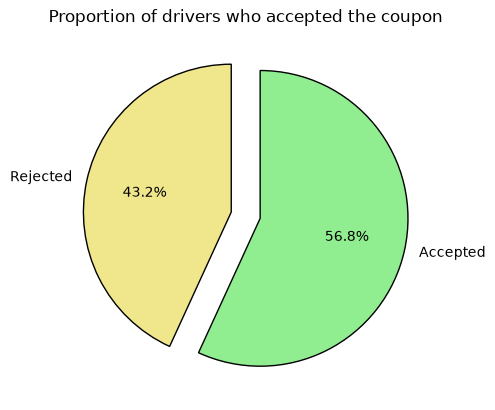

In [241]:
# Count the frequency of each value in the 'Y' column and sort by index (0 first, then 1)
counts = data['Y'].value_counts().sort_index()   # 0 first, then 1

# Create a pie chart to visualize the proportion of accepted vs rejected coupons
plt.pie(
    counts,  # Data values for the pie chart
    labels=['Rejected', 'Accepted'],  # Labels for each slice
    colors =  ['khaki','lightgreen'],  # Custom colors for each slice
    autopct='%1.1f%%',  # Display percentages with 1 decimal place
    startangle=90,  # Start the first slice at 90 degrees (top of circle)
    wedgeprops={'edgecolor': 'black'},  # Add black borders around each slice
    explode = [0.1, 0.1]  # Separate both slices from center by 0.1 units
)
# Add a descriptive title to the pie chart
plt.title('Proportion of drivers who accepted the coupon')
plt.show()

5. Use a bar plot to visualize the `coupon` column.

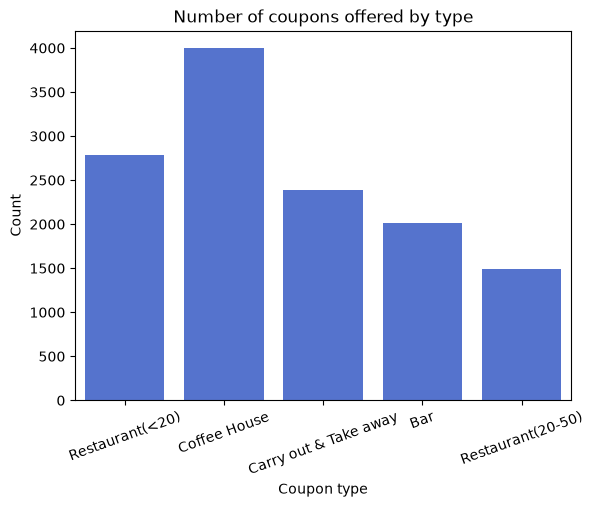

In [ ]:
# Create a count plot to visualize the distribution of coupon types
sns.countplot(data=data, x='coupon',
              color='royalblue')
# Set the title for the plot
plt.title('Number of coupons offered by type')
# Label the x-axis
plt.xlabel('Coupon type')
# Label the y-axis
plt.ylabel('Count')
# Rotate x-axis labels by 20 degrees for better readability
plt.xticks(rotation=20)
plt.show()

6. Use a histogram to visualize the temperature column.

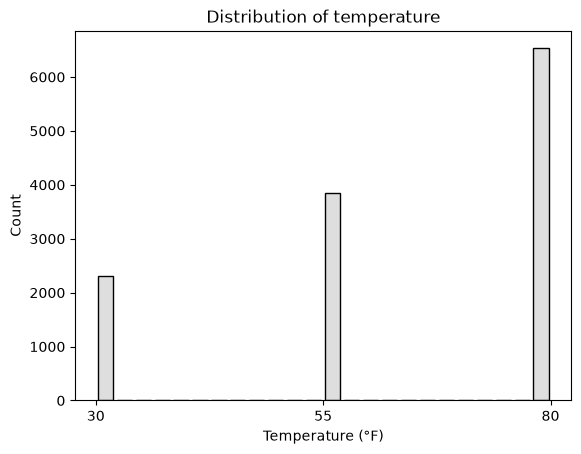

In [239]:
# Create a histogram to visualize the distribution of temperature values
sns.histplot(data=data, x='temperature', color='lightgray', shrink=0.8)

# Set the title for the histogram
plt.title('Distribution of temperature')

# Label the x-axis with units
plt.xlabel('Temperature (°F)')

# Label the y-axis to indicate frequency count
plt.ylabel('Count')

# Set x-axis ticks to show all unique temperature values in the dataset
plt.xticks(data['temperature'].unique())
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [136]:
# Filter the dataset to include only rows where the coupon type is 'Bar'
bar_coupons = data[data['coupon'] == 'Bar']

2. What proportion of bar coupons were accepted?


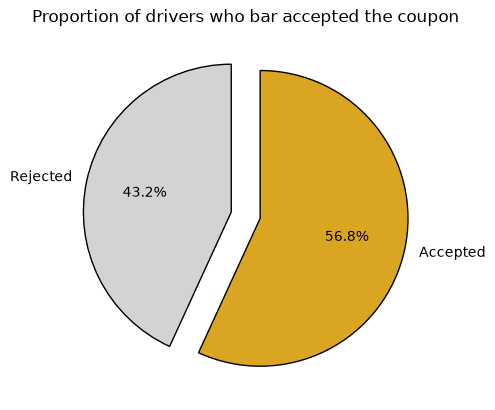

In [265]:
# Count the frequency of each value in the 'Y' column (0 for rejected, 1 for accepted)
# Sort by index to ensure 0 (rejected) comes before 1 (accepted)
bar_cpn_counts = bar_coupons['Y'].value_counts().sort_index()   # 0 first, then 1

# Create a pie chart showing the proportion of coupon acceptance
plt.pie(
    counts,  # Data values for each slice
    labels=['Rejected', 'Accepted'],  # Labels for each slice
    colors =  ['lightgray', 'goldenrod'],  # Colors for rejected and accepted slices
    autopct='%1.1f%%',  # Display percentages with 1 decimal place
    startangle=90,  # Start the first slice at 90 degrees (top of circle)
    wedgeprops={'edgecolor': 'black'},  # Add black borders around pie slices
    explode = [0.1, 0.1]  # Separate both slices from center by 0.1 units
)
# Add title to the pie chart
plt.title('Proportion of drivers who bar accepted the coupon')
plt.show()

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


3 or fewer times a month: 37.07%
More than 3 times a month: 76.88%


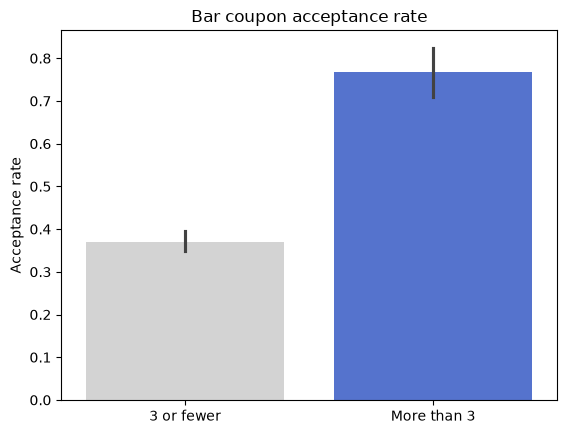

In [237]:
# Calculate acceptance rate for drivers who go to bars 3 or fewer times per month
rate_low = bar_coupons[bar_coupons['Bar'].isin(['never', 'less1', '1~3'])]['Y'].mean()
# Calculate acceptance rate for drivers who go to bars more than 3 times per month
rate_high = bar_coupons[bar_coupons['Bar'].isin(['4~8', 'gt8'])]['Y'].mean()

# Display the acceptance rates as percentages
print(f'3 or fewer times a month: {rate_low:.2%}')
print(f'More than 3 times a month: {rate_high:.2%}')

# Create a new column to categorize bar frequency into two groups
bar_coupons['rate'] = np.where(bar_coupons['Bar'].isin(['4~8', 'gt8']),
                                    'More than 3', '3 or fewer')
# Create a bar plot comparing acceptance rates between the two frequency groups
sns.barplot(data=bar_coupons, x='rate', y='Y',
            hue='rate', hue_order=['3 or fewer', 'More than 3'],
            palette=['lightgray', 'royalblue'], legend=False)
plt.title('Bar coupon acceptance rate')
plt.xlabel('')
plt.ylabel('Acceptance rate')
plt.show()

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [129]:
# check unique values in age column for the people who go to bar_cou
bar_coupons['age'].unique()

<ArrowStringArray>
['21', '46', '26', '31', '41', '50plus', '36', 'below21']
Length: 8, dtype: str

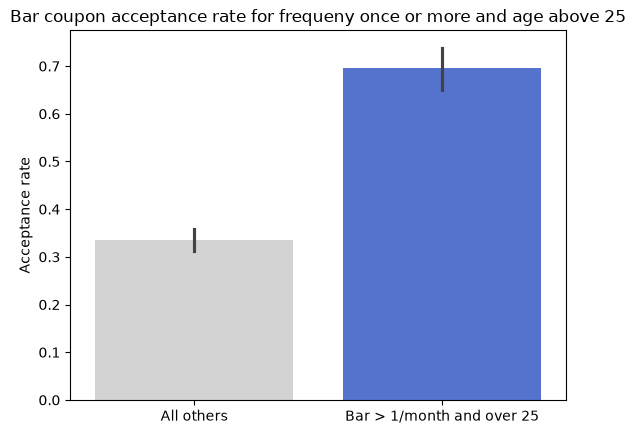

In [267]:
# Create a binary indicator for customers who visit bars more than once per month AND are over 25
bar_coupons['rate_over_25'] = np.where(
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) & (bar_coupons['age'].isin(over_25)),
    'Yes',
    'No'
)

# Create a bar plot comparing acceptance rates between the two groups
ax = sns.barplot(data=bar_coupons, x='rate_over_25', y='Y',
                 order=['No', 'Yes'],  # Order bars: 'No' first, then 'Yes'
                 hue='rate_over_25', hue_order=['No', 'Yes'],  # Color mapping
                 palette=['lightgray', 'royalblue'])  # Custom colors, no legend

# Customize x-axis labels for better readability
ax.set_xticks([0, 1], ['All others', 'Bar > 1/month and over 25'])
# Add plot title and axis labels
plt.title('Bar coupon acceptance rate for frequeny once or more and age above 25')
plt.xlabel('')  # Remove x-axis label (descriptive tick labels are sufficient)
plt.ylabel('Acceptance rate')
plt.show()

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


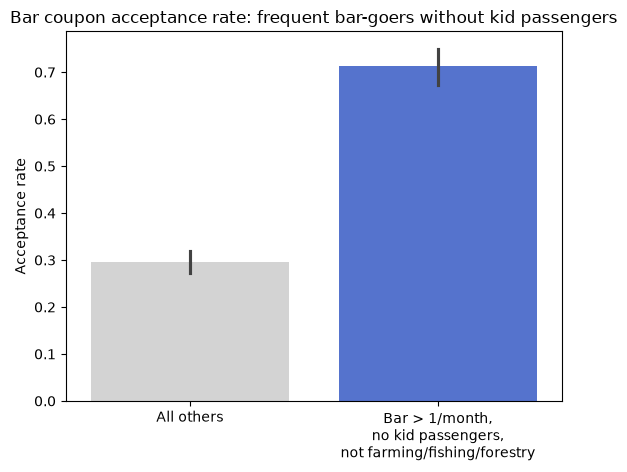

In [235]:
# Create a new column to identify drivers who meet specific criteria:
# - Go to bars more than once per month (1~3, 4~8, or gt8 times)
# - Don't have kid passengers
# - Don't work in farming, fishing, or forestry occupations
bar_coupons['rate_no_kid'] = np.where(
    (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_coupons['passanger'] != 'Kid(s)') &
    (bar_coupons['occupation'] != 'Farming Fishing & Forestry'),
    'Yes',
    'No'
)

# Create a bar plot showing acceptance rates for the two groups
ax = sns.barplot(data=bar_coupons, x='rate_no_kid', y='Y',
                 order=['No', 'Yes'],
                 hue='rate_no_kid', hue_order=['No', 'Yes'],
                 palette=['lightgray', 'royalblue'], legend=False)

# Customize x-axis labels to be more descriptive
ax.set_xticks([0, 1], ['All others', 'Bar > 1/month,\nno kid passengers,\nnot farming/fishing/forestry'])
plt.title('Bar coupon acceptance rate: frequent bar-goers without kid passengers')
plt.xlabel('')
plt.ylabel('Acceptance rate')
plt.show()

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



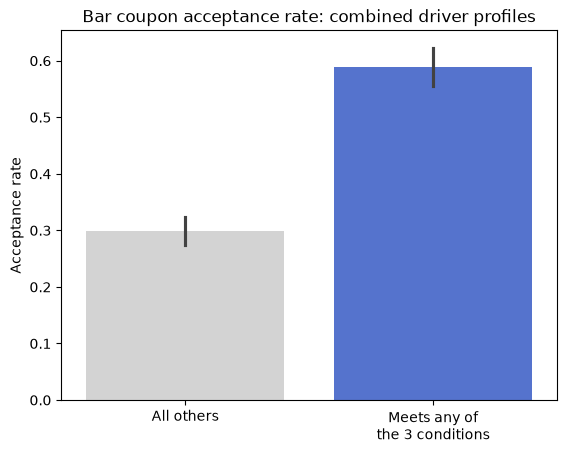

rate_combined
No     0.298147
Yes    0.588918
Name: Y, dtype: float64

In [234]:
# Define age groups for drivers under 30
under_30 = ['below21', '21', '26']
# Define income categories for drivers earning under $50k
income_under_50k = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']

# Create a new column to categorize drivers based on three conditions:
# 1. Goes to bars AND has no kids AND is not widowed
# 2. Goes to bars AND is under 30 years old  
# 3. Frequently visits cheap restaurants AND has low income
bar_coupons['rate_combined'] = np.where(
    (
        # Condition 1: Bar visitors without kids who are not widowed
        (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
        (bar_coupons['passanger'] != 'Kid(s)') &
        (bar_coupons['maritalStatus'] != 'Widowed')
    ) |
    (
        # Condition 2: Bar visitors under 30 years old
        (bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])) &
        (bar_coupons['age'].isin(under_30))
    ) |
    (
        # Condition 3: Frequent cheap restaurant visitors with low income
        (bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])) &
        (bar_coupons['income'].isin(income_under_50k))
    ),
    'Yes',  # If any condition is met
    'No'    # If no conditions are met
)

# Create bar plot comparing acceptance rates between the two groups
ax = sns.barplot(data=bar_coupons, x='rate_combined', y='Y',
                 order=['No', 'Yes'],
                 hue='rate_combined', hue_order=['No', 'Yes'],
                 palette=['lightgray', 'royalblue'], legend=False)

# Customize x-axis labels for better readability
ax.set_xticks([0, 1], ['All others', 'Meets any of\nthe 3 conditions'])
plt.title('Bar coupon acceptance rate: combined driver profiles')
plt.xlabel('')
plt.ylabel('Acceptance rate')
plt.show()

# Calculate and display the actual acceptance rates for each group
bar_coupons.groupby('rate_combined')['Y'].mean()

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [ ]:
Key Findings

Overall acceptance: About 56.8% of drivers accepted bar coupons, compared with 57% across all coupon types.
Bar-going frequency matters most: Drivers who visit bars more than three times a month had a 77% acceptance rate, compared with 37% for others. This suggests coupons appeal most to people who already visit bars regularly.
Passengers matter: Frequent bar-goers traveling without children had a 71% acceptance rate, compared with 30% for others. Having children in the car may discourage bar visits.
Age has less influence: Frequent bar-goers over 25 had a 70% acceptance rate, compared with 34% for others. Younger frequent bar-goers also showed high acceptance, suggesting that habits matter more than age.
Income and restaurant habits have limited impact: Combining the conditions resulted in a 59% acceptance rate, compared with 42% for others. Including people who frequently visit cheap restaurants broadened the group and reduced the overall effect.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

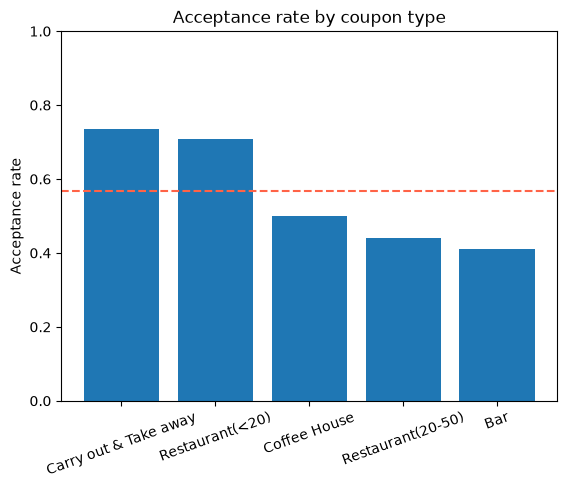

In [263]:
# Group data by coupon type and calculate mean acceptance rate for each type
# Sort the results in descending order by acceptance rate
rates = data.groupby('coupon')['Y'].mean().sort_values(ascending=False)

# Create a bar chart showing acceptance rates by coupon type
plt.bar(rates.index, rates.values)

# Add a horizontal reference line showing the overall average acceptance rate
plt.axhline(data['Y'].mean(), color='tomato', linestyle='--', label='All coupons average')

# Set chart title and y-axis label
plt.title('Acceptance rate by coupon type')
plt.ylabel('Acceptance rate')


# Set y-axis limits from 0 to 1 (representing 0% to 100%)
plt.ylim(0, 1)

# Rotate x-axis labels for better readability
plt.xticks(rotation=20)
plt.show()

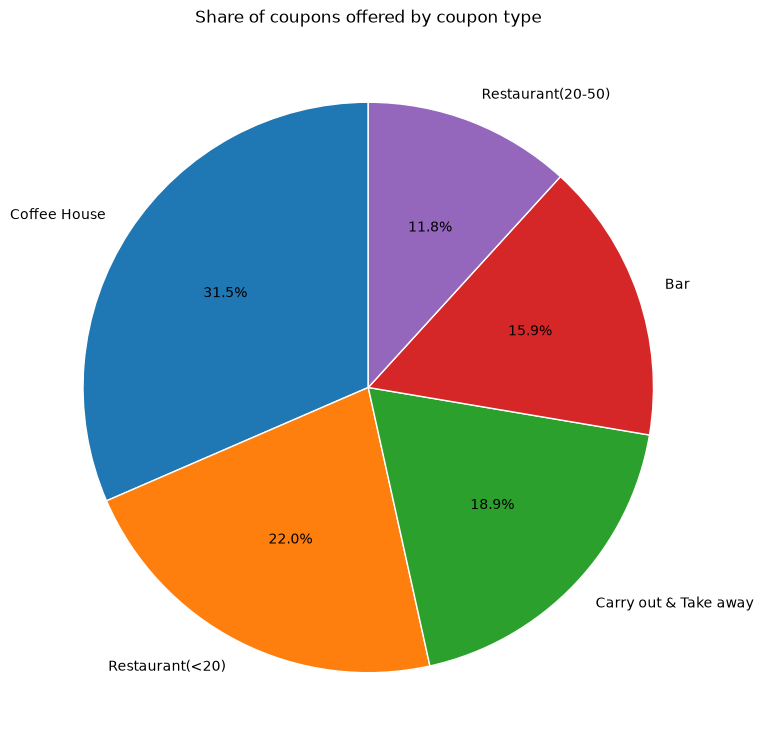

In [ ]:
# Number of coupons offered for each coupon type.
coupon_counts = data['coupon'].value_counts()

# Pie chart showing each coupon type's share of all coupons offered
plt.pie(
    coupon_counts.values,
    labels=coupon_counts.index,
    autopct='%1.1f%%',           # show each slice's percentage
    startangle=90,               # start the first slice at the top
    wedgeprops={'edgecolor': 'white'}
)

plt.title('Share of coupons offered by coupon type')
plt.tight_layout()
plt.show()

In [155]:
#Coffee House Coupons
# Filter the dataset to only include rows where the coupon type is 'Coffee House'
coffee = data[data['coupon'] == 'Coffee House']

# Calculate the baseline acceptance rate for Coffee House coupons (proportion of accepted coupons)
# This will serve as a reference point for comparing acceptance rates across different groups
coffee_rate = coffee['Y'].mean()

# Display summary statistics for the Coffee House coupon dataset
print(f'Coffee House coupons: {coffee.shape[0]} rows')
print(f'Overall acceptance rate: {coffee_rate:.1%}')

Coffee House coupons: 3996 rows
Overall acceptance rate: 49.9%


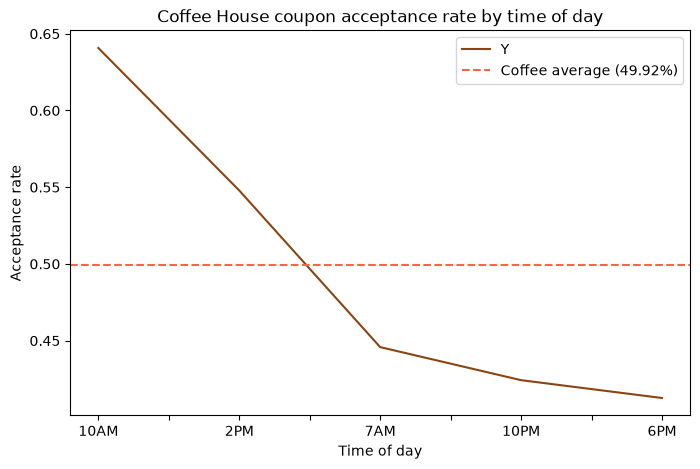

In [269]:
# Group coffee data by time and calculate mean acceptance rate for each time period
coffee_time_rate = coffee.groupby('time')['Y'].mean().sort_values(ascending=False)
coffee_time_rate

# Create a line plot showing acceptance rates by time of day
ax = coffee_time_rate.plot(kind='line', color='saddlebrown', figsize=(8, 5))
# Add horizontal reference line showing overall coffee coupon acceptance rate
ax.axhline(coffee_rate, color='tomato', linestyle='--', label=f'Coffee average ({coffee_rate:.2%})')

# Customize plot appearance and labels
plt.title('Coffee House coupon acceptance rate by time of day')
plt.xlabel('Time of day')
plt.ylabel('Acceptance rate')
plt.xticks(rotation=0)
plt.legend()
plt.show()

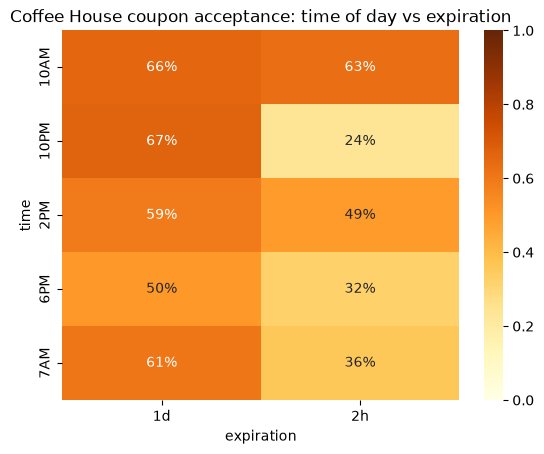

In [211]:
# Acceptance rate for each combination of time of day and coupon expiration
## with  unstack() expiration values become columns
coffee_time_exp = coffee.groupby(['time', 'expiration'])['Y'].mean().unstack()

# Heatmap of acceptance rates
sns.heatmap(coffee_time_exp, annot=True, fmt='.0%', cmap='YlOrBr', vmin=0, vmax=1)
plt.title('Coffee House coupon acceptance: time of day vs expiration')
plt.show()

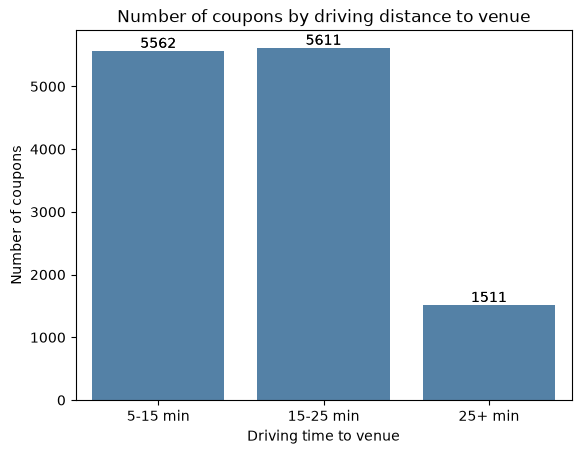

In [231]:
# Combine the distance flags into one readable category
# Use np.select to create a new categorical variable based on multiple conditions
# Priority order: 25+ min, then 15-25 min, then 5-15 min, with <5 min as default
data['distance'] = np.select(
    [data['toCoupon_GEQ25min'] == 1, data['toCoupon_GEQ15min'] == 1, data['toCoupon_GEQ5min'] == 1],
    ['25+ min', '15-25 min','5-15 min'],
    default='<5 min'
)

# Display the frequency distribution of the distance categories
data['distance'].value_counts()

# Create a count plot to visualize the distribution of coupons by distance
br = sns.countplot(data=data, x='distance',  color='steelblue')
# Add count labels on top of each bar for better readability
br.bar_label(br.containers[0])
# Add descriptive title and axis labels
plt.title('Number of coupons by driving distance to venue')
plt.xlabel('Driving time to venue')
plt.ylabel('Number of coupons')
# Combine the distance flags into one readable category
# Use np.select to create a new categorical variable based on multiple conditions
# Priority order: 25+ min, then 15-25 min, then 5-15 min, with <5 min as default
data['distance'] = np.select(
    [data['toCoupon_GEQ25min'] == 1, data['toCoupon_GEQ15min'] == 1, data['toCoupon_GEQ5min'] == 1],
    ['25+ min', '15-25 min','5-15 min'],
    default='<5 min'
)

# Display the frequency distribution of the distance categories
data['distance'].value_counts()

# Create a count plot to visualize the distribution of coupons by distance
br = sns.countplot(data=data, x='distance',  color='steelblue')
# Add count labels on top of each bar for better readability
br.bar_label(br.containers[0])
# Add descriptive title and axis labels
plt.title('Number of coupons by driving distance to venue')
plt.xlabel('Driving time to venue')
plt.ylabel('Number of coupons')
plt.show()

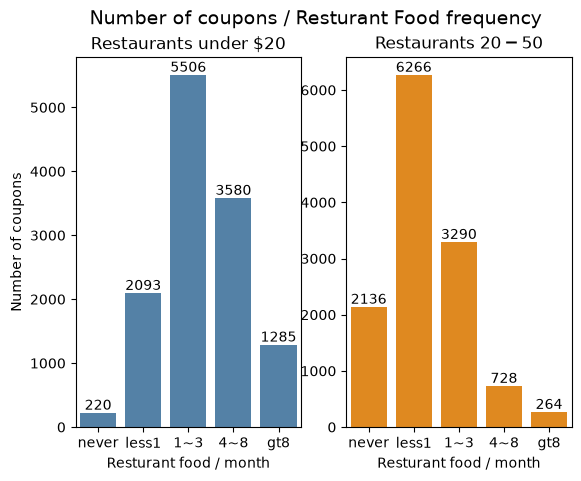

In [261]:
# Logical order for the monthly visit-frequency categories
freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']

# Create a figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2)

# Restaurants under $20
# Create count plot for restaurant visits under $20 with specified order and styling
sns.countplot(data=data, x='RestaurantLessThan20', order=freq_order, color='steelblue', ax=axes[0])
# Add value labels on top of each bar
axes[0].bar_label(axes[0].containers[0])
# Set title and axis labels for the first subplot
axes[0].set_title('Restaurants under $20')
axes[0].set_xlabel('Resturant food / month')
axes[0].set_ylabel('Number of coupons')

# Restaurants $20-$50
# Create count plot for restaurant visits $20-$50 with specified order and styling
sns.countplot(data=data, x='Restaurant20To50', order=freq_order, color='darkorange', ax=axes[1])
# Add value labels on top of each bar
axes[1].bar_label(axes[1].containers[0])
# Set title and axis labels for the second subplot (no y-label to avoid redundancy)
axes[1].set_title('Restaurants $20-$50')
axes[1].set_xlabel('Resturant food / month')
axes[1].set_ylabel('')

# Add overall title for the entire figure
fig.suptitle('Number of coupons / Resturant Food frequency', fontsize=14)
# Display the plot
plt.show()